In [1]:
# Install into the Python environment selected for this notebook.
import subprocess
import sys
ULTRALYTICS_VERSION = "8.4.120"
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "ultralytics==" + ULTRALYTICS_VERSION, "pyyaml"], check=True)
try:
    import google.colab
    RUNNING_ON_COLAB = True
except ImportError:
    RUNNING_ON_COLAB = False
print("Running on Colab:", RUNNING_ON_COLAB)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
ERROR: Operation cancelled by user


KeyboardInterrupt: 

In [4]:
import json
import os
import random

import torch
from ultralytics import YOLO

print("torch    :", torch.__version__)
print("GPU      :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

if not torch.cuda.is_available():
    print("")
    print("No GPU. In Colab: Runtime, Change runtime type, T4 GPU.")
    print("Training on CPU works but takes far longer than the lab allows.")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
torch    : 2.14.1+cu130
GPU      : Tesla T4


In [5]:
from pathlib import Path
if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/C389"
else:
    PROJECT_ROOT = str(Path.cwd() / "C389")
WORK_DIR = os.path.join(PROJECT_ROOT, "runs", "L3")
os.makedirs(WORK_DIR, exist_ok=True)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("WORK_DIR:", WORK_DIR)

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/C389
WORK_DIR: /content/drive/MyDrive/C389/runs/L3


In [8]:
from pathlib import Path
from zipfile import ZipFile

ZIP_PATH = Path.home() / "Downloads" / "ca1.v1i.yolo26.zip"
if RUNNING_ON_COLAB:
    ZIP_PATH = Path("/content/ca1.v1i.yolo26.zip")
    if not ZIP_PATH.is_file():
        from google.colab import files
        uploaded = files.upload()
        matches = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(matches) != 1:
            raise ValueError("Upload exactly one dataset ZIP.")
        ZIP_PATH = Path(matches[0]).resolve()
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Dataset ZIP not found: {ZIP_PATH}. Edit ZIP_PATH above.")

# Keep extraction local to the runtime for faster training in Colab.
extract_dir = (Path("/content/ca1_dataset") if RUNNING_ON_COLAB
               else Path(PROJECT_ROOT) / "data" / "ca1_dataset")
extract_dir.mkdir(parents=True, exist_ok=True)
with ZipFile(ZIP_PATH) as archive:
    for member in archive.infolist():
        target = (extract_dir / member.filename).resolve()
        if not target.is_relative_to(extract_dir.resolve()):
            raise ValueError(f"Invalid archive path: {member.filename}")
    archive.extractall(extract_dir)
configs = list(extract_dir.rglob("data.yaml"))
if len(configs) != 1:
    raise ValueError(f"Expected one data.yaml, found {len(configs)} under {extract_dir}")
DATASET_DIR = str(configs[0].parent.resolve())
DATA_YAML = str(configs[0].resolve())
USING_SAMPLE_DATA = False
print("Dataset:", DATASET_DIR)

Saving ca1.v1i.yolo26.zip to ca1.v1i.yolo26.zip
Dataset: /content/ca1_dataset


In [9]:
import yaml

def read_class_names(yaml_path):
    with open(yaml_path, encoding="utf-8") as handle:
        names = yaml.safe_load(handle)["names"]
    if isinstance(names, dict):
        names = [names[key] for key in sorted(names, key=int)]
    return list(names)

CLASS_NAMES = read_class_names(DATA_YAML)
EXPECTED_CLASSES = ["person_left", "person_left_wheel", "person_right", "person_right_wheel"]
if CLASS_NAMES != EXPECTED_CLASSES:
    raise ValueError(f"Unexpected class order: {CLASS_NAMES}; expected {EXPECTED_CLASSES}")
print("Class IDs:", dict(enumerate(CLASS_NAMES)))

Class IDs: {0: 'person_left', 1: 'person_left_wheel', 2: 'person_right', 3: 'person_right_wheel'}


In [10]:
# Write a separate training config; preserve the exported data.yaml.
with open(DATA_YAML, encoding="utf-8") as handle:
    dataset_config = yaml.safe_load(handle)
dataset_config["path"] = Path(DATASET_DIR).as_posix()
for split, folder in (("train", "train"), ("val", "valid"), ("test", "test")):
    if not (Path(DATASET_DIR) / folder / "images").is_dir():
        raise FileNotFoundError(f"Missing {folder}/images under {DATASET_DIR}")
    dataset_config[split] = f"{folder}/images"
dataset_config["names"] = CLASS_NAMES
dataset_config["nc"] = len(CLASS_NAMES)
DATA_YAML = str(Path(DATASET_DIR) / "data_training.yaml")
with open(DATA_YAML, "w", encoding="utf-8") as handle:
    yaml.safe_dump(dataset_config, handle, sort_keys=False)
print(Path(DATA_YAML).read_text(encoding="utf-8"))

train: train/images
val: valid/images
test: test/images
nc: 4
names:
- person_left
- person_left_wheel
- person_right
- person_right_wheel
roboflow:
  workspace: varicks-workspace-c34mz
  project: ca1-8wvgy
  version: 1
  license: Private
  url: https://app.roboflow.com/varicks-workspace-c34mz/ca1-8wvgy/1
path: /content/ca1_dataset



In [11]:
SPLIT_FOLDERS = ["train", "valid", "test"]


def count_images(dataset_dir, split):
    """How many images one split folder holds, 0 when the folder is missing."""
    image_dir = os.path.join(dataset_dir, split, "images")
    if not os.path.isdir(image_dir):
        return 0
    return sum(1 for name in os.listdir(image_dir)
               if name.lower().endswith((".jpg", ".jpeg", ".png")))


SPLIT_COUNTS = {split: count_images(DATASET_DIR, split) for split in SPLIT_FOLDERS}
for split in SPLIT_FOLDERS:
    print("%-6s %4d images" % (split, SPLIT_COUNTS[split]))

if not SPLIT_COUNTS["train"]:
    raise ValueError("The version has no training images. Generate it again in "
                     "Roboflow with images in Train.")

# The split every result below is judged on. Ultralytics calls the valid folder "val".
EVAL_FOLDER = "test" if SPLIT_COUNTS["test"] else "valid"
EVAL_SPLIT = "test" if EVAL_FOLDER == "test" else "val"
if EVAL_FOLDER == "valid":
    print("")
    print("No test images, so the final score is read on valid instead.")

train   317 images
valid    84 images
test     48 images


In [12]:
def image_paths(dataset_dir, split, limit=None):
    """List the images in one split, in filename order."""
    image_dir = os.path.join(dataset_dir, split, "images")
    names = sorted(name for name in os.listdir(image_dir)
                   if name.lower().endswith((".jpg", ".jpeg", ".png")))
    if limit:
        names = names[:limit]
    return [os.path.join(image_dir, name) for name in names]


def to_detections(result, class_names):
    """Turn one Ultralytics result into plain dictionaries.

    The same shape is used in the service in Lesson 4, so the counting code
    written below is the code that ships.
    """
    detections = []
    boxes = result.boxes
    if boxes is None:
        return detections
    for index in range(len(boxes)):
        class_id = int(boxes.cls[index].item())
        name = class_names[class_id] if class_id < len(class_names) else str(class_id)
        detections.append({
            "class_name": name,
            "confidence": round(float(boxes.conf[index].item()), 3),
            "box": [round(float(value), 1) for value in boxes.xyxy[index].tolist()],
        })
    return detections


from ultralytics.utils import ASSETS

BASELINE_MODEL = "yolo26n.pt"
pretrained = YOLO(BASELINE_MODEL)
pretrained_names = [pretrained.names[key] for key in sorted(pretrained.names)]

# A real photograph first, then one image from this dataset. The photograph is
# what carries the point, and it is here because a model trained on photographs
# has never seen a drawing and reports nothing on the sample set.
baseline_paths = [os.path.join(str(ASSETS), "bus.jpg")]
baseline_paths += image_paths(DATASET_DIR, EVAL_FOLDER, limit=1)

for path in baseline_paths:
    result = pretrained.predict(path, conf=0.35, verbose=False)[0]
    detections = to_detections(result, pretrained_names)
    print(os.path.basename(path))
    for detection in detections:
        print("   %-12s %.2f" % (detection["class_name"], detection["confidence"]))
    if not detections:
        print("   nothing detected")

bus.jpg
   bus          0.92
   person       0.91
   person       0.91
   person       0.87
   person       0.53
6289353751407565651_jpg.rf.23b4186509b06e575a961a925b8d86e5.jpg
   person       0.90
   person       0.86
   person       0.85
   bicycle      0.83
   car          0.83
   person       0.78
   person       0.46


In [13]:
MODEL_VARIANT = "yolo26n.pt"
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16

In [17]:
# fliplr is pre-written and must stay at 0.0.
#
# Horizontal flip augmentation mirrors the image and keeps the original label. A
# flipped person_left is a person moving right, still labelled person_left, so
# the model is taught the opposite of the truth on half the data. Nothing in the
# output reveals it: the curves look normal and the score looks reasonable. This
# is the one setting in this notebook that is not a choice.
FLIP_LEFT_RIGHT = 0.0

RUN_NAME = "people_counting_baseline"

missing = [name for name, value in (
    ("MODEL_VARIANT", MODEL_VARIANT), ("EPOCHS", EPOCHS),
    ("IMAGE_SIZE", IMAGE_SIZE), ("BATCH_SIZE", BATCH_SIZE)) if value is None]
if missing:
    raise ValueError("Set these before launching: %s" % ", ".join(missing))

training_images = len(image_paths(DATASET_DIR, "train"))
steps_per_epoch = max(1, training_images // BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS

print("model variant :", MODEL_VARIANT)
print("epochs        :", EPOCHS)
print("image size    :", IMAGE_SIZE)
print("batch size    :", BATCH_SIZE)
print("fliplr        :", FLIP_LEFT_RIGHT, "(must be 0.0)")
print("")
print("training images  : %d" % training_images)
print("optimiser steps  : %d per epoch, %d in total" % (steps_per_epoch, total_steps))

if total_steps < 300:
    print("")
    print("That is a small number of steps. Expect a model that finds roughly the")
    print("right places and is not confident about any of them, which shows up as")
    print("counts of zero in Section 8. Raise the epochs rather than the threshold.")

model variant : yolo26n.pt
epochs        : 100
image size    : 640
batch size    : 16
fliplr        : 0.0 (must be 0.0)

training images  : 317
optimiser steps  : 19 per epoch, 1900 in total


In [18]:
model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.204 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ca1_dataset/data_training.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

In [19]:
trained = YOLO(BEST_WEIGHTS)
metrics = trained.val(data=DATA_YAML, split=EVAL_SPLIT, verbose=False)

PER_CLASS = {}
for index, class_id in enumerate(metrics.ap_class_index):
    PER_CLASS[CLASS_NAMES[int(class_id)]] = {
        "precision": float(metrics.box.p[index]),
        "recall": float(metrics.box.r[index]),
        "ap50": float(metrics.box.ap50[index]),
        "ap50_95": float(metrics.box.ap[index]),
    }

print("%-14s %9s %7s %8s %9s" % ("class", "precision", "recall", "mAP@.5", "mAP@.5:.95"))
for name in CLASS_NAMES:
    if name in PER_CLASS:
        row = PER_CLASS[name]
        print("%-14s %9.3f %7.3f %8.3f %9.3f"
              % (name, row["precision"], row["recall"], row["ap50"], row["ap50_95"]))

scores = [PER_CLASS[name]["ap50"] for name in PER_CLASS]
if len(scores) > 1:
    gap = max(scores) - min(scores)
    print("")
    print("gap between the best and worst class, mAP@.5: %.3f" % gap)
    if gap >= 0.10:
        print("")
        print("That is a wide gap, and it points at the data rather than the model.")
        print("One direction has either fewer annotated instances than the other or")
        print("less consistent ones. Check the class balance before changing any")
        print("training setting, because no setting fixes an imbalance.")
    else:
        print("The four classes have similar AP50 scores. Inspect per-class recall too.")

Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1141.7±277.0 MB/s, size: 56.0 KB)
val: Scanning /content/ca1_dataset/test/labels... 48 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 1.7Kit/s 0.0s
val: New cache created: /content/ca1_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5it/s 2.0s
                   all         48         94      0.802      0.775      0.809      0.549
Speed: 9.1ms preprocess, 7.0ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val
class          precision  recall   mAP@.5 mAP@.5:.95
person_left        0.759   0.725    0.726     0.472
person_left_wheel     0.869   0.846    0.880     0.583
person_right       0.724   0.639    0.713     0.436
person_righ

results.png


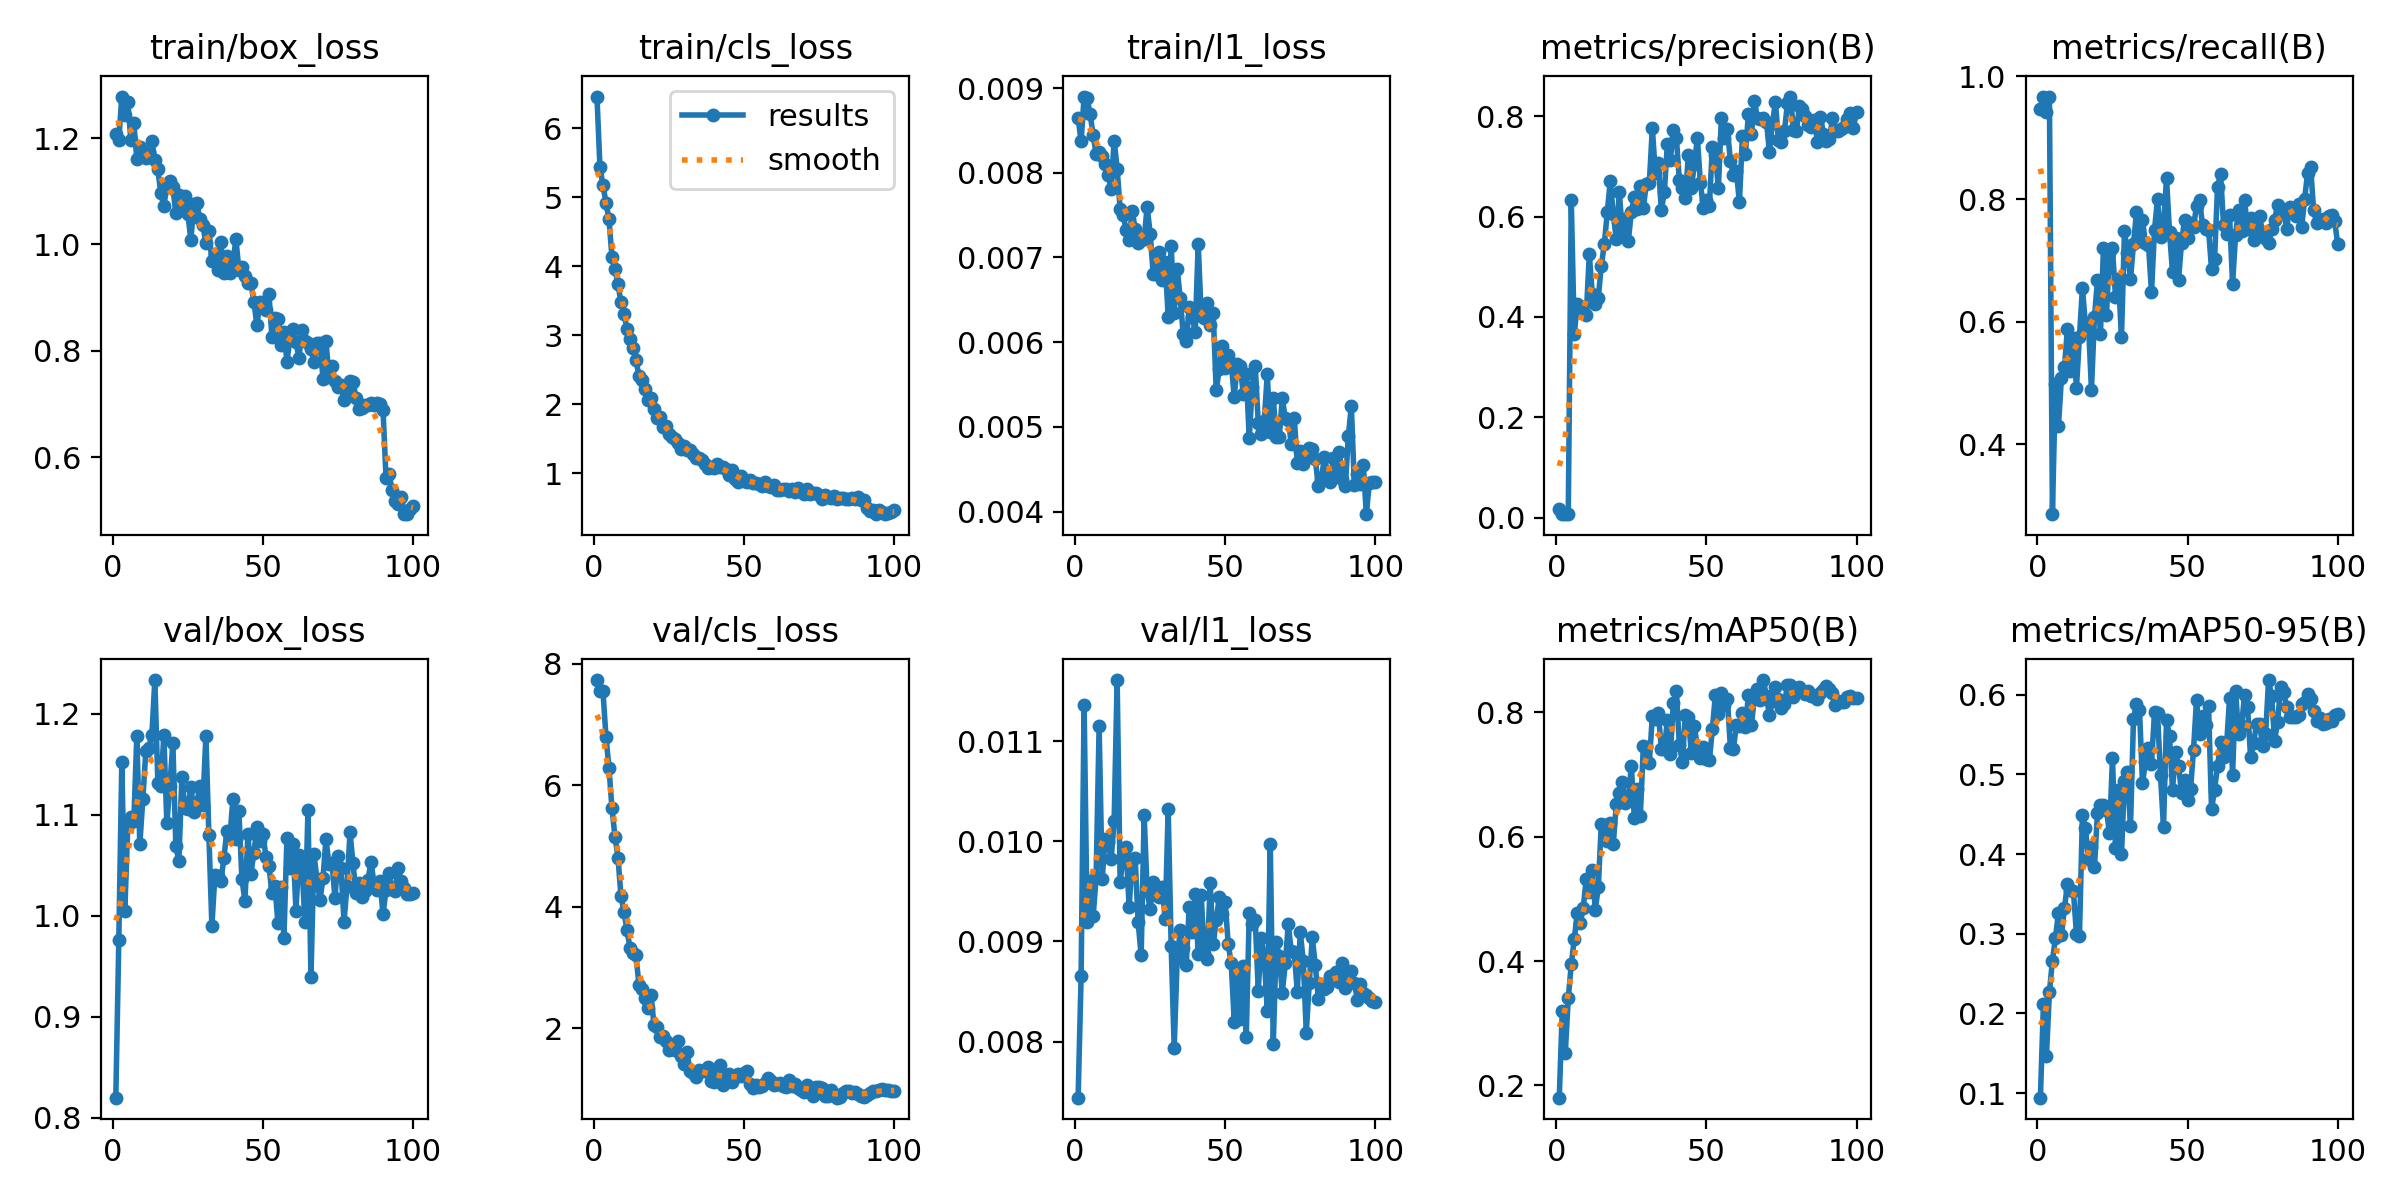

BoxPR_curve.png


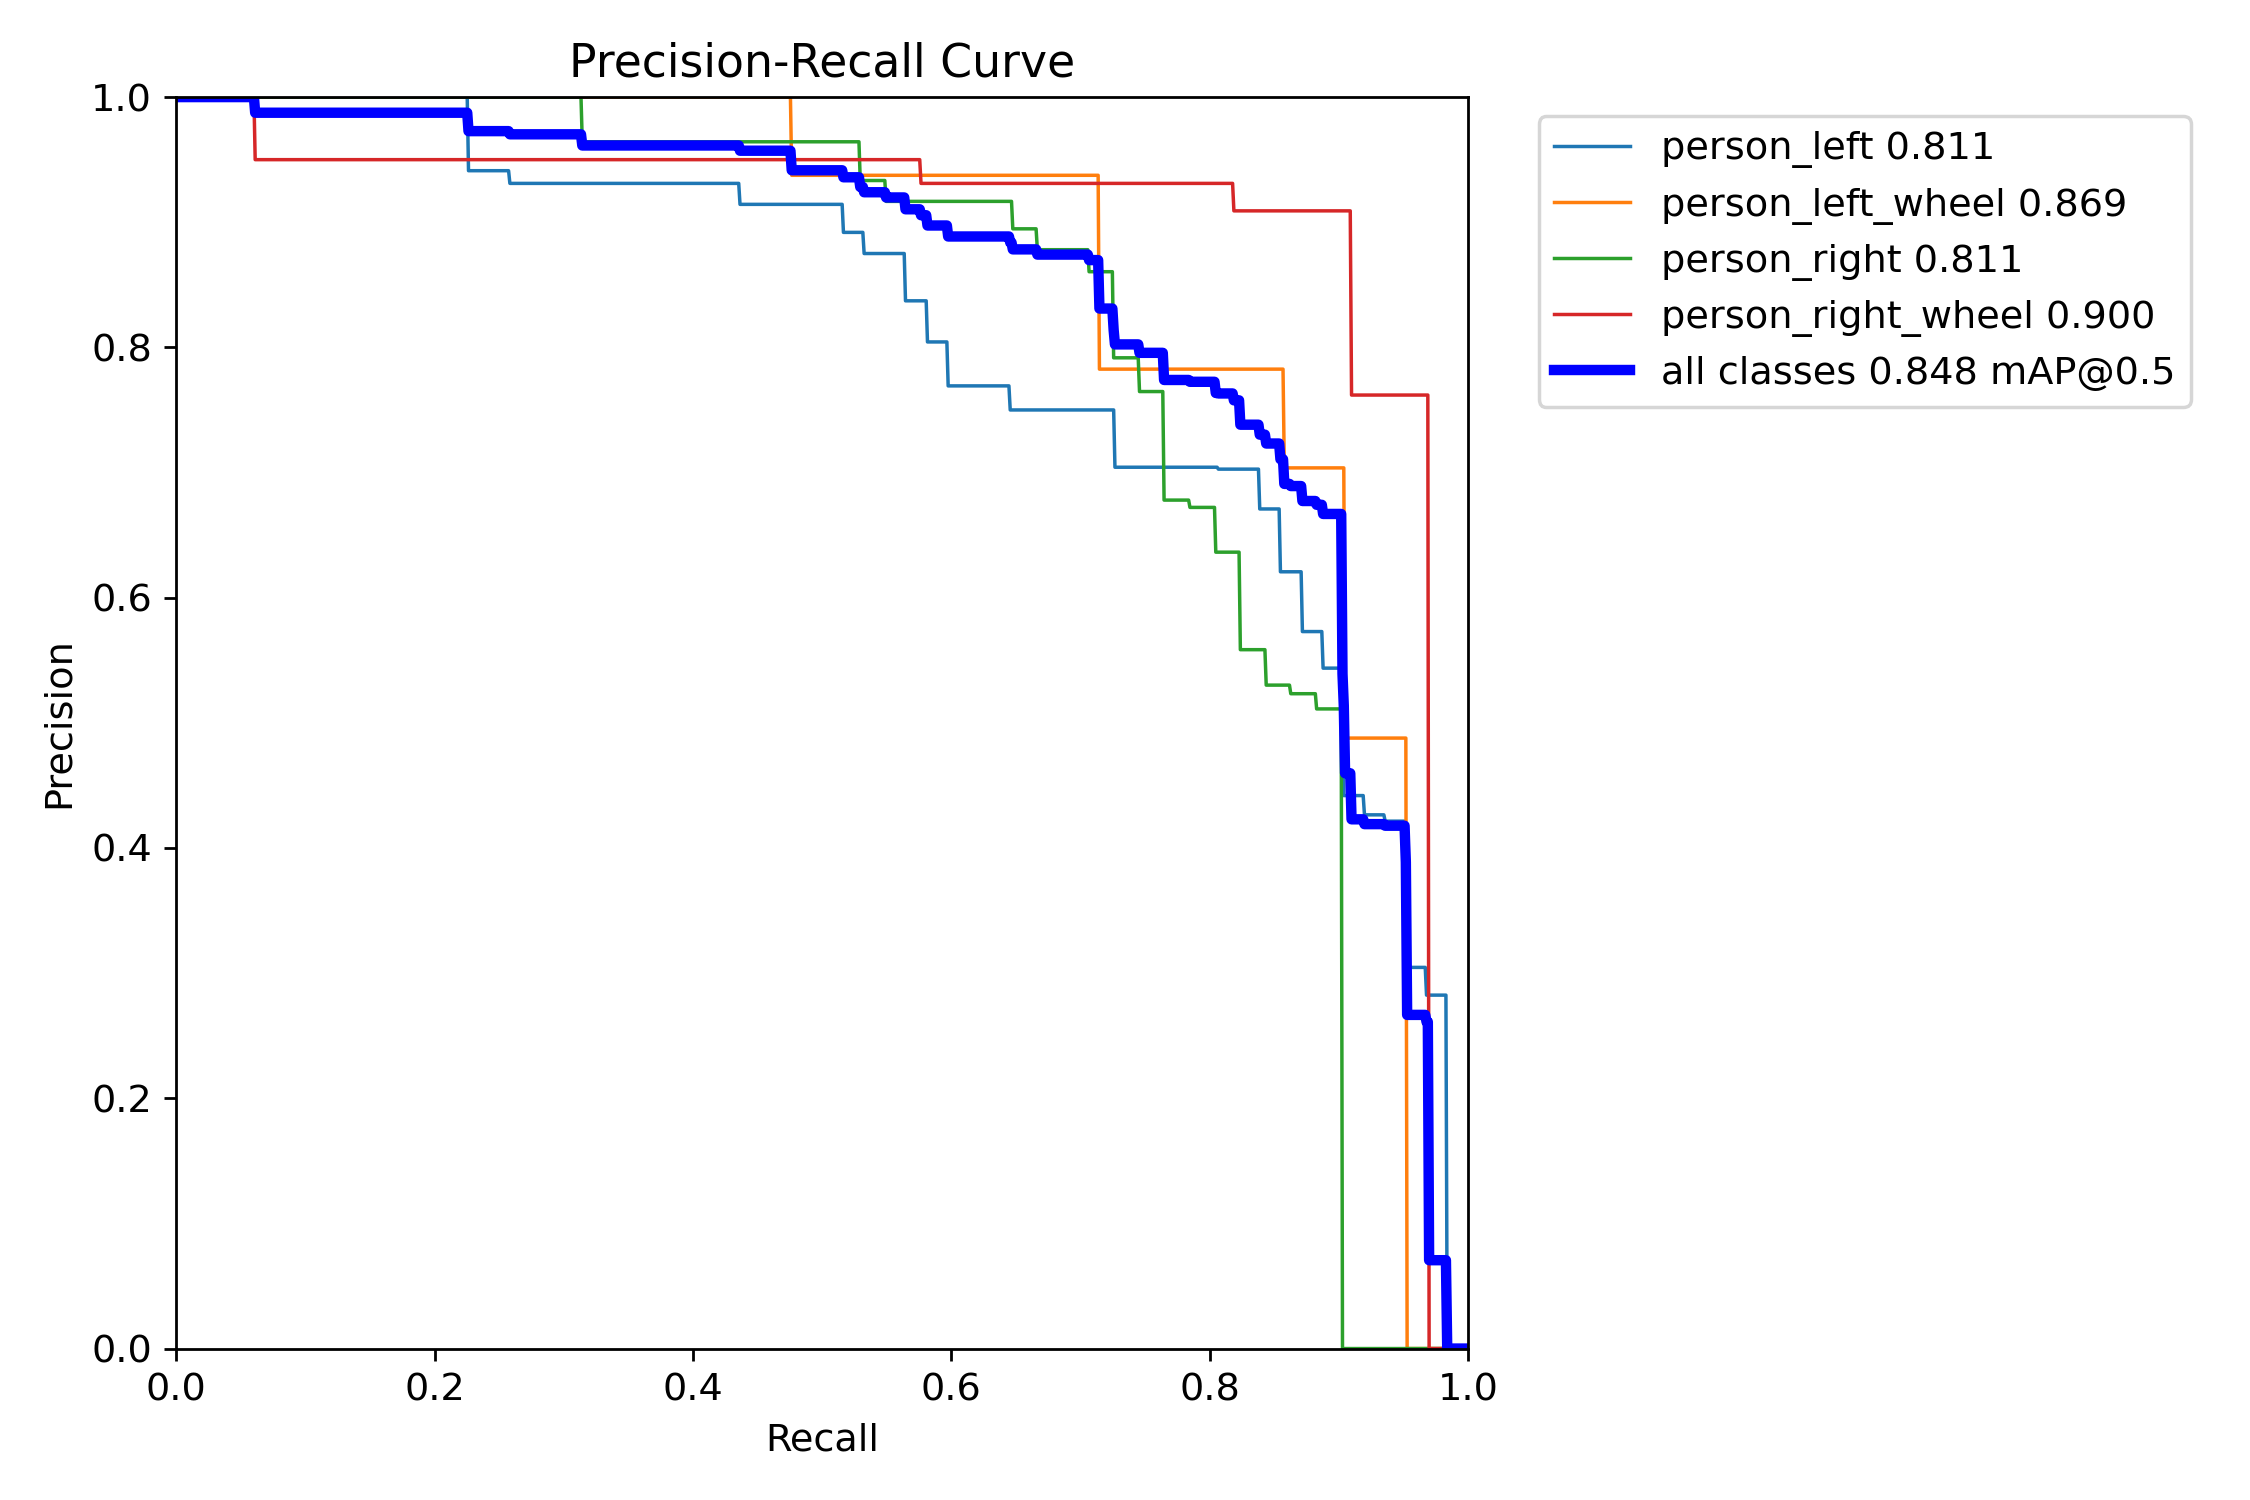

confusion_matrix.png


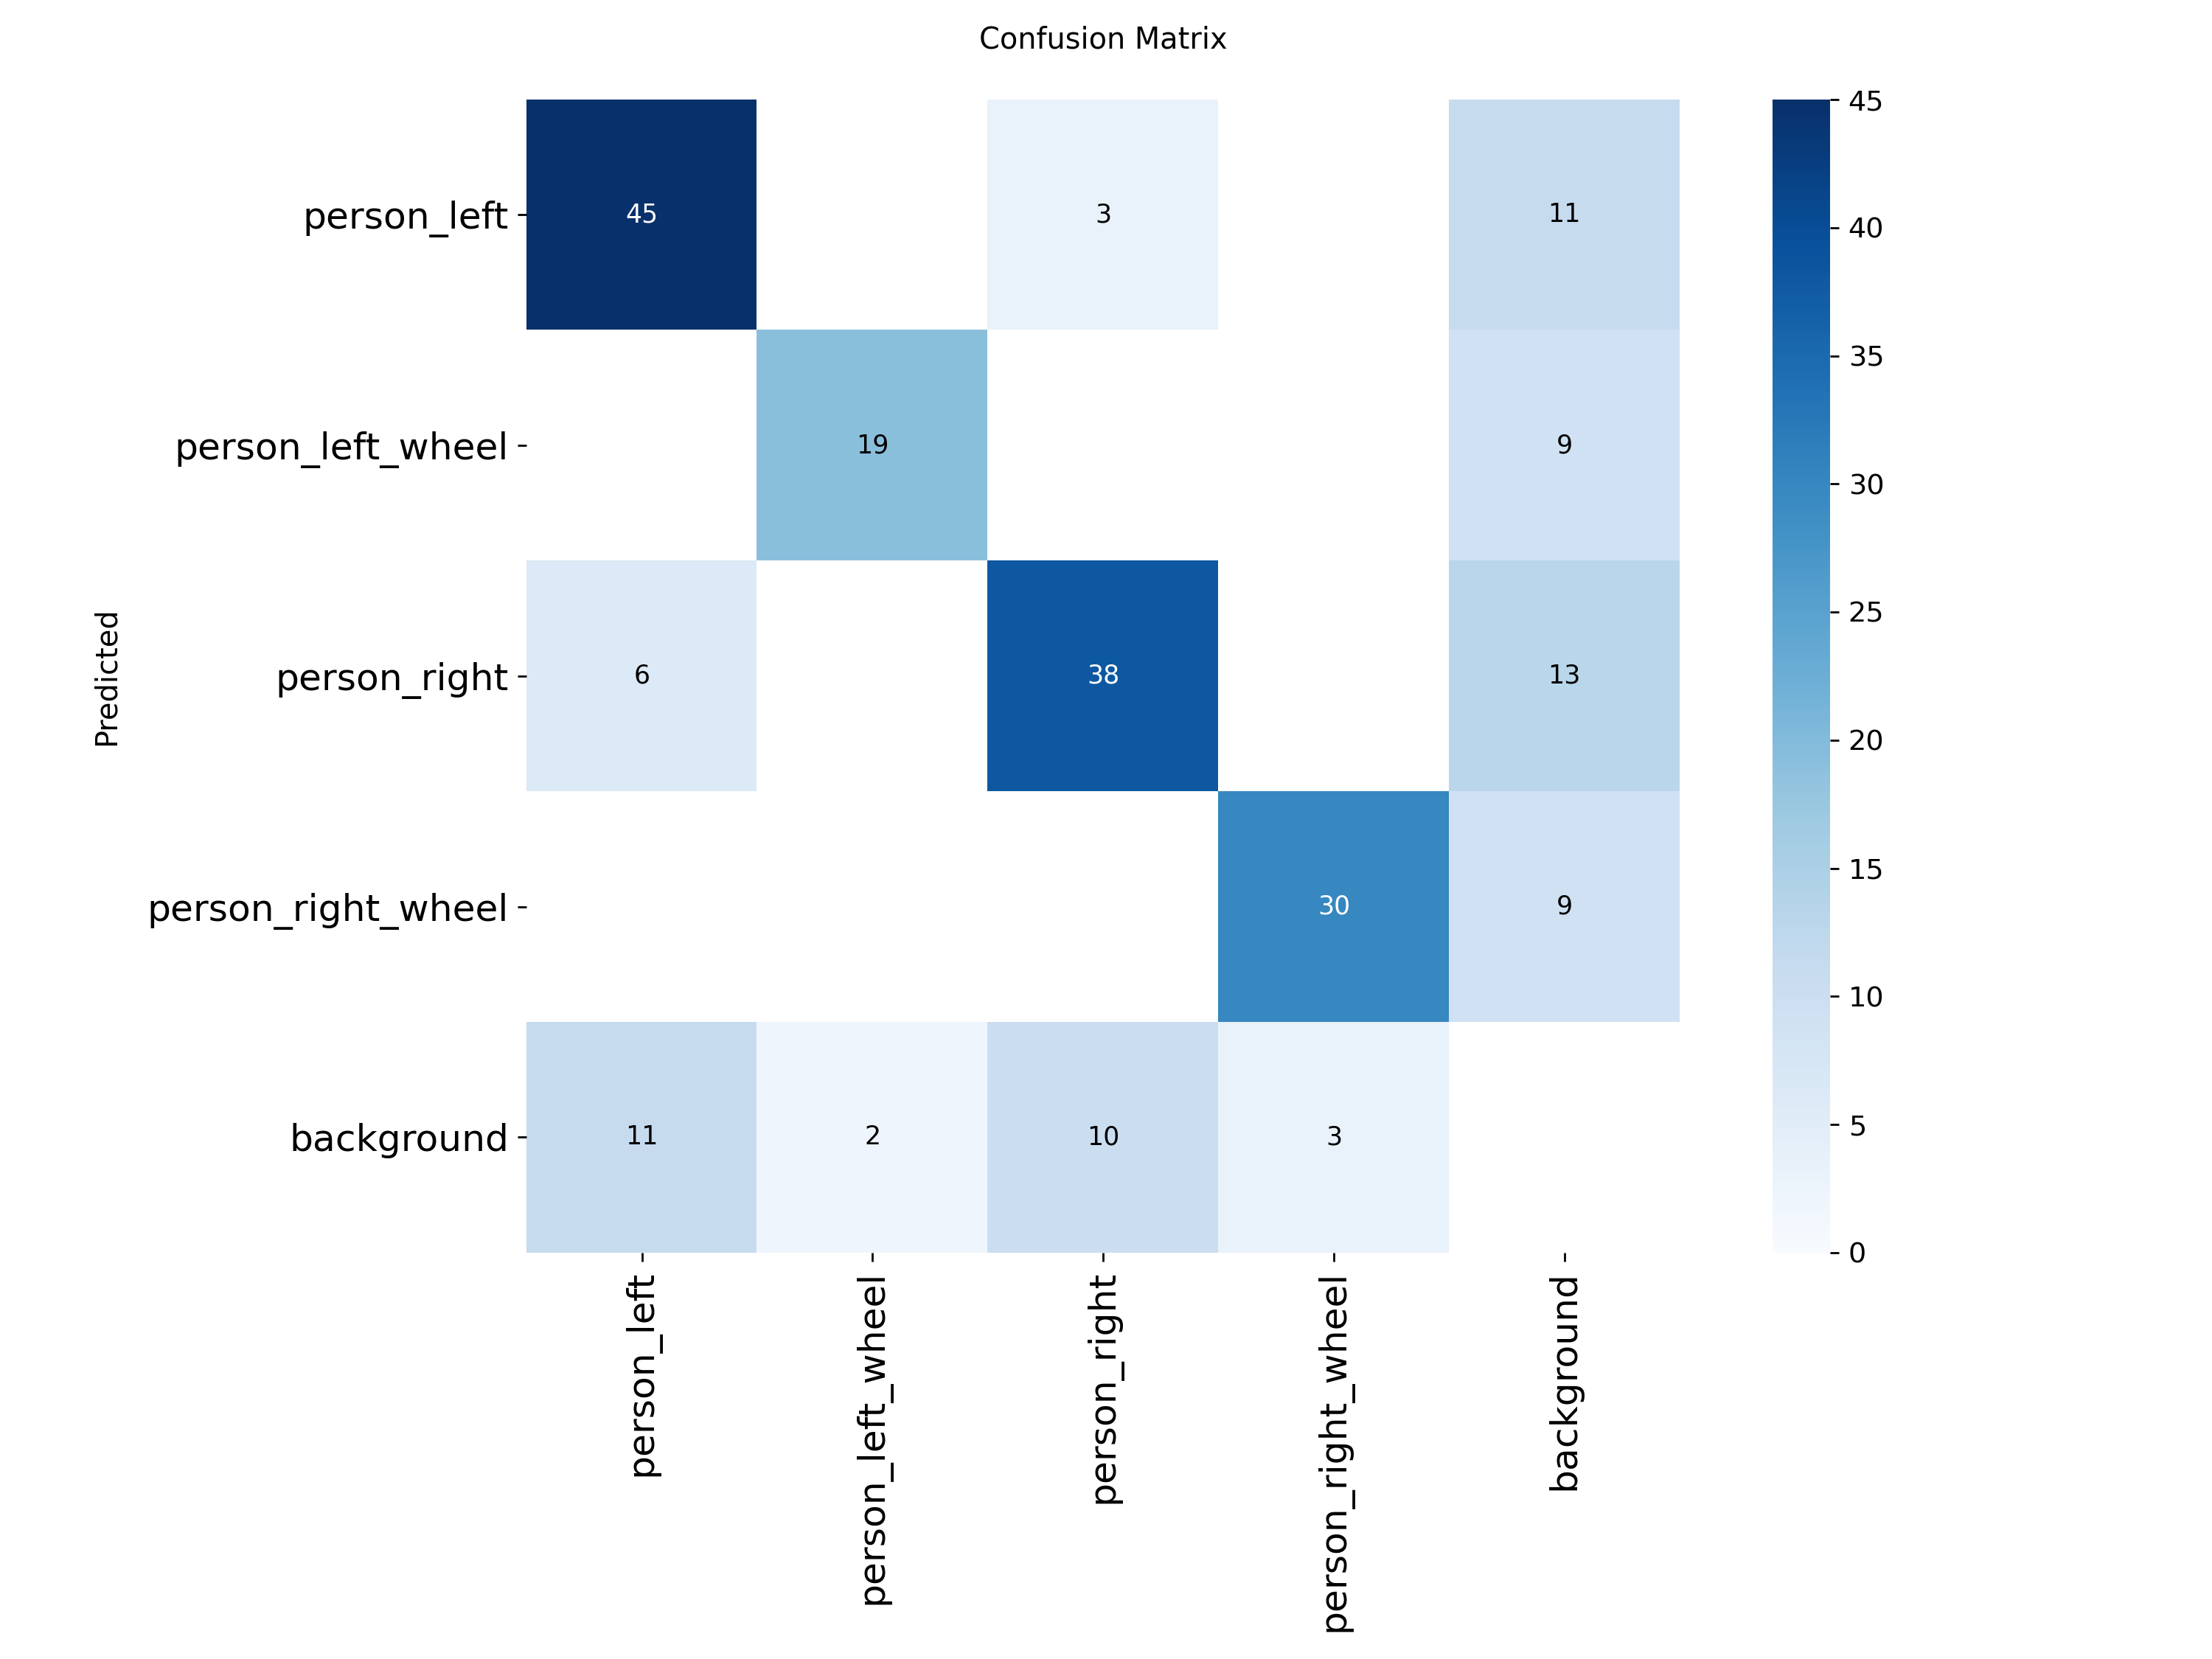

In [20]:
from IPython.display import Image as ShowImage, display
from PIL import Image as PILImage

for name in ("results.png", "BoxPR_curve.png", "confusion_matrix.png"):
    path = os.path.join(RUN_DIR, name)
    if os.path.exists(path):
        print(name)
        display(ShowImage(filename=path, width=760))

In [22]:
def truth_for(image_path, class_names):
    """Read the annotated classes for one image from its label file."""
    label_path = image_path.replace(os.sep + "images" + os.sep,
                                    os.sep + "labels" + os.sep)
    label_path = os.path.splitext(label_path)[0] + ".txt"
    found = []
    if os.path.exists(label_path):
        with open(label_path, encoding="utf-8") as handle:
            for line in handle:
                if line.strip():
                    class_id = int(line.split()[0])
                    if class_id < len(class_names):
                        found.append(class_names[class_id])
    return sorted(found)


CONFIDENCE_FOR_REVIEW = 0.40

print("%-34s %-26s %s" % ("image", "annotated", "predicted"))
for path in image_paths(DATASET_DIR, EVAL_FOLDER):
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    predicted = sorted(d["class_name"] for d in to_detections(result, CLASS_NAMES))
    truth = truth_for(path, CLASS_NAMES)
    flag = "  <-- differs" if predicted != truth else ""
    print("%-34s %-26s %s%s"
          % (os.path.basename(path)[:34], ", ".join(truth) or "none",
             ", ".join(predicted) or "none", flag))

image                              annotated                  predicted
6289353751407565651_jpg.rf.23b4186 person_left, person_right_wheel person_left, person_left_wheel, person_right_wheel  <-- differs
6289353751407565677_jpg.rf.190521a person_left_wheel          person_left_wheel
6289353751407565684_jpg.rf.82a4260 person_left_wheel, person_right_wheel person_left_wheel, person_right_wheel
6289353751407565700_jpg.rf.0364950 person_right_wheel         person_right_wheel
6289353751407565717_jpg.rf.f492008 person_right_wheel         person_right_wheel
6289353751407565722_jpg.rf.b30fe63 person_right_wheel         person_right_wheel
6289353751407565726_jpg.rf.0db4784 person_right_wheel         person_right_wheel
6289353751407565743_jpg.rf.0b208e8 person_left_wheel          person_left_wheel
6289353751407565753_jpg.rf.be42645 person_left_wheel          person_left_wheel
6289353751407565754_jpg.rf.d3a51cb person_left_wheel          person_left_wheel
6289353751407565764_jpg.rf.952f065 person_

6289353751407565651_jpg.rf.23b4186509b06e575a961a925b8d86e5.jpg


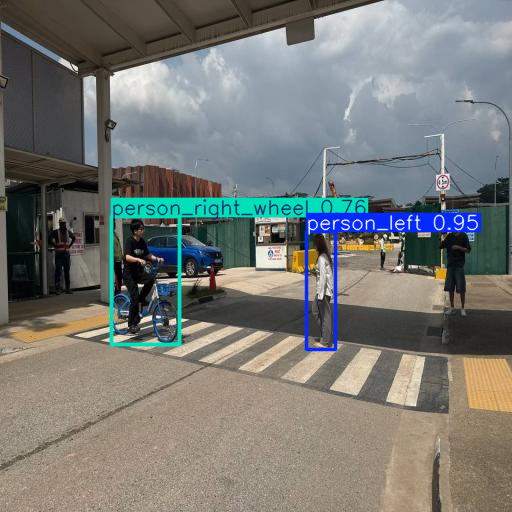

In [ ]:
# Look at the ones that differed. Reading the picture is what tells you whether
# the model missed a person entirely or found the person and read the direction
# backwards. Those are two different problems with two different fixes.
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=8):
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    predicted = sorted(d["class_name"] for d in to_detections(result, CLASS_NAMES))
    if predicted != truth_for(path, CLASS_NAMES):
        print(os.path.basename(path))
        # result.plot() returns a BGR array. PIL wants RGB, so the channels are
        # reversed before display.
        display(PILImage.fromarray(result.plot()[:, :, ::-1]))
        break
else:
    print("Nothing in the first eight test images differed.")

In [23]:
# Named once, here, and used everywhere below. The value is a decision, and it is
# one of the things the sheet asks to be justified.
CONFIDENCE_THRESHOLD = 0.40

In [24]:
best_confidence = 0.0
for path in image_paths(DATASET_DIR, EVAL_FOLDER):
    result = trained.predict(path, conf=0.001, verbose=False)[0]
    for detection in to_detections(result, CLASS_NAMES):
        if detection["confidence"] > best_confidence:
            best_confidence = detection["confidence"]

print("highest confidence anywhere on the %s split : %.3f" % (EVAL_FOLDER, best_confidence))
print("the threshold chosen above : %.2f" % CONFIDENCE_THRESHOLD)

if best_confidence < CONFIDENCE_THRESHOLD:
    print("")
    print("Nothing reaches the threshold, so every count below will be zero.")
    print("The threshold is not the problem and lowering it is not the fix. The")
    print("model is under trained: it has learned roughly where people are and")
    print("has not learned to be sure. Go back to Section 4, raise the epochs,")
    print("and run again. The optimiser step count printed there is the number")
    print("to change.")

highest confidence anywhere on the test split : 0.996
the threshold chosen above : 0.40


In [25]:
def count_people(model, image_path, class_names, threshold):
    """Count the people in one image, grouped by direction class.

    Args:
        model: the trained YOLO model
        image_path: path to a single image
        class_names: the ordered class list read from data.yaml
        threshold: detections below this confidence are dropped

    Returns:
        (counts, kept), where counts maps every class name to a whole number and
        kept is the list of detections that survived the threshold

    Requirement:
        Every class appears in counts, including the ones at zero. A caller
        reading the result should never have to guess whether a missing name
        means none were found or means the class does not exist.

        An image with nobody in it is a valid result of zero, not an error.
    """
    result = model.predict(image_path, conf=0.01, verbose=False)[0]
    detections = to_detections(result, class_names)

    kept = []
    for detection in detections:
        if detection["confidence"] >= threshold:
            kept.append(detection)

    counts = {}
    for name in class_names:
        counts[name] = 0
    for detection in kept:
        counts[detection["class_name"]] = counts[detection["class_name"]] + 1

    return counts, kept

In [26]:
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=4):
    counts, kept = count_people(trained, path, CLASS_NAMES, CONFIDENCE_THRESHOLD)
    print("%-34s %s" % (os.path.basename(path)[:34],
                        "  ".join("%s=%d" % (n, counts[n]) for n in CLASS_NAMES)))

6289353751407565651_jpg.rf.23b4186 person_left=1  person_left_wheel=1  person_right=0  person_right_wheel=1
6289353751407565677_jpg.rf.190521a person_left=0  person_left_wheel=1  person_right=0  person_right_wheel=0
6289353751407565684_jpg.rf.82a4260 person_left=0  person_left_wheel=1  person_right=0  person_right_wheel=1
6289353751407565700_jpg.rf.0364950 person_left=0  person_left_wheel=0  person_right=0  person_right_wheel=1


In [27]:
sample_path = image_paths(DATASET_DIR, EVAL_FOLDER, limit=1)[0]
print(os.path.basename(sample_path))
print("")

everything = to_detections(
    trained.predict(sample_path, conf=0.001, verbose=False)[0], CLASS_NAMES)
everything.sort(key=lambda detection: detection["confidence"], reverse=True)

print("every detection in this image, most confident first")
for detection in everything[:12]:
    print("   %-14s %.3f" % (detection["class_name"], detection["confidence"]))
if len(everything) > 12:
    print("   ... and %d more below these" % (len(everything) - 12))
print("")
print("%-11s %s" % ("threshold", "counts"))
for threshold in (0.15, 0.25, 0.40, 0.60, 0.80):
    counts, kept = count_people(trained, sample_path, CLASS_NAMES, threshold)
    print("%-11.2f %s  (%d detections kept)"
          % (threshold, "  ".join("%s=%d" % (n, counts[n]) for n in CLASS_NAMES),
             len(kept)))

6289353751407565651_jpg.rf.23b4186509b06e575a961a925b8d86e5.jpg

every detection in this image, most confident first
   person_left    0.948
   person_right_wheel 0.755
   person_left_wheel 0.414
   person_right_wheel 0.031
   person_left    0.003
   person_left_wheel 0.002
   person_right   0.001

threshold   counts
0.15        person_left=1  person_left_wheel=1  person_right=0  person_right_wheel=1  (3 detections kept)
0.25        person_left=1  person_left_wheel=1  person_right=0  person_right_wheel=1  (3 detections kept)
0.40        person_left=1  person_left_wheel=1  person_right=0  person_right_wheel=1  (3 detections kept)
0.60        person_left=1  person_left_wheel=0  person_right=0  person_right_wheel=1  (2 detections kept)
0.80        person_left=1  person_left_wheel=0  person_right=0  person_right_wheel=0  (1 detections kept)


In [28]:
import shutil

ARTIFACT_DIR = os.path.join(PROJECT_ROOT, "artifacts", "L3")
os.makedirs(ARTIFACT_DIR, exist_ok=True)

shutil.copy(BEST_WEIGHTS, os.path.join(ARTIFACT_DIR, "best.pt"))

with open(os.path.join(ARTIFACT_DIR, "baseline_metrics.json"), "w",
          encoding="utf-8") as handle:
    json.dump({
        "classes": CLASS_NAMES,
        "per_class": PER_CLASS,
        "confidence_threshold": CONFIDENCE_THRESHOLD,
        "config": {"model_variant": MODEL_VARIANT, "epochs": EPOCHS,
                   "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
                   "fliplr": FLIP_LEFT_RIGHT},
        "used_sample_data": USING_SAMPLE_DATA,
    }, handle, indent=1)

print("best.pt and baseline_metrics.json saved to", ARTIFACT_DIR)
print("Lesson 4 loads the weights from there. Lesson 5 compares against the metrics.")

best.pt and baseline_metrics.json saved to /content/drive/MyDrive/C389/artifacts/L3
Lesson 4 loads the weights from there. Lesson 5 compares against the metrics.
